In [93]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Deterministic Sankey from method

In [94]:
# Generate sbm and adjacency matrix
import sys
import matplotlib.pyplot as plt
sys.path.append('..')
from pygraphon.graphons import Graphon
from pygraphon.graphons import StepGraphon
from experiments.utils_generators import AssociativeFullyRandom
k = 2
n = 400
# theta init
theta_intra_min, theta_intra_max = 0.4, 0.8
theta_inter_min, theta_inter_max = 0.1, 0.3
import numpy as np
np.random.seed(420)
theta = AssociativeFullyRandom(
                    K=k,
                    min_inside_classes=theta_intra_min,
                    max_inside_classes=theta_intra_max,
                    min_outside_classes=theta_inter_min,
                    max_outside_classes=theta_inter_max,
                )
graphon = StepGraphon(theta.Theta, bandwidthHist=1 / k)
adjacency_matrix=graphon.draw(n=n, exchangeable=False)
print(graphon.get_theta())

[[0.74726659 0.17200129]
 [0.17200129 0.65189141]]


In [95]:
#import smoothnethist
from pygraphon.estimators import SmoothNetHist

est = SmoothNetHist(bandwidth=1/(2*k))
est.fit(adjacency_matrix)

In [96]:
import numpy as np
list_graphons = [est.all_cluster_graphons[i].get_theta()[np.triu_indices(est.all_cluster_graphons[i].get_theta().shape[0])] for i in range(len(est.all_cluster_graphons))]

sort_indices = np.argsort(list_graphons[-1])

for i in range(len(list_graphons)):
    list_graphons[i] = list_graphons[i][sort_indices]
graphons_array = np.array(list_graphons)
graphons_array = np.rot90(np.insert(graphons_array, 0, np.ones(graphons_array.shape[1]), axis=0), k=3)

In [97]:
#makes list into pandas dataframe
import pandas as pd
pd.set_option('display.float_format', '{:.3f}'.format)
columns = []
for i in range(len(list_graphons)):
    columns.append("SmoothNetHist_" + str(len(list_graphons)-i))
columns.append("Count")

def list_to_df(array, columns):
    df = pd.DataFrame(array, columns=columns)
    return df

df = list_to_df(graphons_array, columns=columns)
df

,SmoothNetHist_7,SmoothNetHist_6,SmoothNetHist_5,SmoothNetHist_4,SmoothNetHist_3,SmoothNetHist_2,SmoothNetHist_1,Count
0,0.129,0.129,0.129,0.129,0.129,0.129,0.174,1.000
1,0.177,0.183,0.183,0.189,0.189,0.189,0.174,1.000
2,0.188,0.183,0.183,0.189,0.189,0.189,0.174,1.000
3,0.201,0.201,0.201,0.189,0.189,0.189,0.174,1.000
4,0.627,0.627,0.634,0.634,0.634,0.634,0.634,1.000
5,0.642,0.642,0.634,0.634,0.634,0.634,0.634,1.000
6,0.700,0.700,0.700,0.700,0.711,0.711,0.711,1.000
7,0.722,0.722,0.722,0.722,0.711,0.711,0.711,1.000
8,0.749,0.749,0.749,0.749,0.749,0.767,0.767,1.000
9,0.785,0.785,0.785,0.785,0.785,0.767,0.767,1.000


# Plotting sankey

In [98]:
import sys
sys.path.insert(0, r"c:\users\arthu\documents\swittz-epfl\phd\code\lib\site-packages")
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [99]:
def find_peak_index(lst):
    for i in range(1, len(lst)):
        if lst[i] < lst[i - 1]:
            return i - 1
    return len(lst) - 1

In [109]:
source_nodes_origin = [0.129, 0.177, 0.188,0.201,0.627,0.642,0.70001,0.722,0.749,0.785, 0.183, 0.634, 0.189, 0.711, 0.767, 0.174, 0.739, 0.704, 0.435]
transform = lambda x : x
source_nodes = [transform(n) for n in source_nodes_origin]
idx = find_peak_index(source_nodes)
print("The original grapghon has", idx+1, "nodes")
# the 0.0001 is to avoid the error of having nodes one the boundaries of [0,1], somehow it messes up the visualization
source_intervals = [0.0001 if i < idx+1 else (i-idx)/len(source_nodes[idx+1:]) for i in range(len(source_nodes))]
nodes = [{"label": str(label)+'_'+str(i)} for i, label in enumerate(sorted(source_nodes))]
intervals_x = [interval for _, interval in sorted(zip(source_nodes, source_intervals))]
intervals_x[intervals_x.index(1)] -= 0.0001
intervals_y = [(i)/len(nodes) for i in range(len(nodes))]
intervals_y[intervals_y.index(0)] += 0.0001
diff_intervals_y = [intervals_y[i+1] - intervals_y[i] for i in range(len(intervals_y)-1)]

#Need to correct the y interval corresponding to 0.70001 because the sankey than is misplaced vertically
index_70001 = transform(0.70001)
index_704 = transform(0.704)
y_70001 = intervals_y[sorted(source_nodes).index(index_70001)]
y_704 = intervals_y[sorted(source_nodes).index(index_704)]
intervals_y[sorted(source_nodes).index(index_70001)] = y_704
intervals_y[sorted(source_nodes).index(index_704)] = y_70001

The original grapghon has 10 nodes


In [110]:
links = [
    {'source': 2, 'target': 3, 'value': 1},
    {'source': 4, 'target': 3, 'value': 1},
    {'source': 8, 'target': 9, 'value': 1},
    {'source': 10, 'target': 9, 'value': 1},
    {'source': 3, 'target': 5, 'value': 2},
    {'source': 6, 'target': 5, 'value': 1},
    {'source': 11, 'target': 13, 'value': 1},
    {'source': 14, 'target': 13, 'value': 1},
    {'source': 16, 'target': 17, 'value': 1},
    {'source': 18, 'target': 17, 'value': 1},
    {'source': 0, 'target': 1, 'value': 1},
    {'source': 5, 'target': 1, 'value': 3},
    {'source': 13, 'target': 15, 'value': 2},
    {'source': 17, 'target': 15, 'value': 2},
    {'source': 9, 'target': 12, 'value': 2},
    {'source': 15, 'target': 12, 'value': 4},
    {'source': 12, 'target': 7, 'value': 6},
    {'source': 1, 'target': 7, 'value': 4},
]

In [111]:
# testing colorbrewer colours
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors

# To get the colors as a list of hex strings:
hex_colors = YlOrRd_9.hex_colors

# Discretise the colors andassign them to the values in source_nodes
import matplotlib
import matplotlib.cm as cm
import matplotlib.colors as colors
import numpy as np
cmap = cm.get_cmap('YlOrRd')
norm = colors.Normalize(vmin=min(source_nodes), vmax=max(source_nodes))
#norm = colors.Normalize(vmin=0, vmax=1)
source_nodes_colors = [matplotlib.colors.rgb2hex(cmap(norm(i))) for i in sorted(source_nodes)]

In [112]:
import plotly.graph_objects as go
import colorsys
import re

def adjust_vividness(color_str, saturation_factor, value_factor):
    # Convert named colors to RGB
    named_colors = {
        "red": (255, 0, 0),
        "blue": (0, 0, 255),
        "green": (0, 128, 0),
        "yellow": (255, 255, 0)
    }
    
    if color_str in named_colors:
        r, g, b = named_colors[color_str]
    elif "#" in color_str:  # Hex format
        r, g, b = tuple(int(color_str.lstrip("#")[i:i+2], 16) for i in (0, 2, 4))
    elif "rgb" in color_str:  # rgb() format
        r, g, b = map(int, re.search(r"rgb\((\d+),\s*(\d+),\s*(\d+)\)", color_str).groups())
    else:
        raise ValueError(f"Unsupported color format: {color_str}")
    
    # Convert RGB to HSV
    h, s, v = colorsys.rgb_to_hsv(r/255.0, g/255.0, b/255.0)
    
    # Adjust saturation and value
    s *= saturation_factor
    v *= value_factor
    
    # Convert HSV back to RGB
    r, g, b = colorsys.hsv_to_rgb(h, s, v)
    return f'rgb({int(r*255)},{int(g*255)},{int(b*255)})'

In [146]:
import plotly.graph_objects as go
import plotly.io as pio
# Define the data

#sorted_links = sorted(links, key=lambda k: k['source']) #this doesnt chnage anything
# Create the figure and subplot
fig = make_subplots(rows=1, cols=1)

# Add the Sankey trace
fig.add_trace(go.Sankey(
    arrangement = "perpendicular",
    node=dict(
        pad=10*len(nodes),  # Adjust the padding between nodes
        thickness=20,  # Adjust the thickness of nodes
        line=dict(color='black', width=1),  # Define the color and width of node lines
        label=[f"{float(node['label']):.3f}" for node in nodes],  # Extract node labels from the 'nodes' list
        x = intervals_x,
        y = intervals_y,
        color = [adjust_vividness(color, 1, 1) for color in source_nodes_colors],
    ),
    link=dict(
        source=[link['source'] for link in links],  # Extract source indices from the 'links' list
        target=[link['target'] for link in links],  # Extract target indices from the 'links' list
        value=[link['value'] for link in links],  # Extract values from the 'links' list
        color = [[adjust_vividness(color, 0.75, 1) for color in source_nodes_colors][link['source']] for link in links],
        line = dict(color = "black", width = 0.25)
    )
))

# Update the layout
fig.update_layout(title_text='kmeans dynamic')
# Save the Sankey diagram as SVG
pio.write_image(fig, 'sankey.svg', format='svg', scale=2)

# Save the Sankey diagram as PNG
pio.write_image(fig, 'sankey.png', format='png', scale=2)

# Save the Sankey diagram as PDF
pio.write_image(fig, 'sankey.pdf', format='pdf', scale=2)

# Show the plot
fig.show()

# Getting SSM from each step of the Sankey

C:\Users\verdeyme\AppData\Local\Temp\ipykernel_12632\3966811668.py:19: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



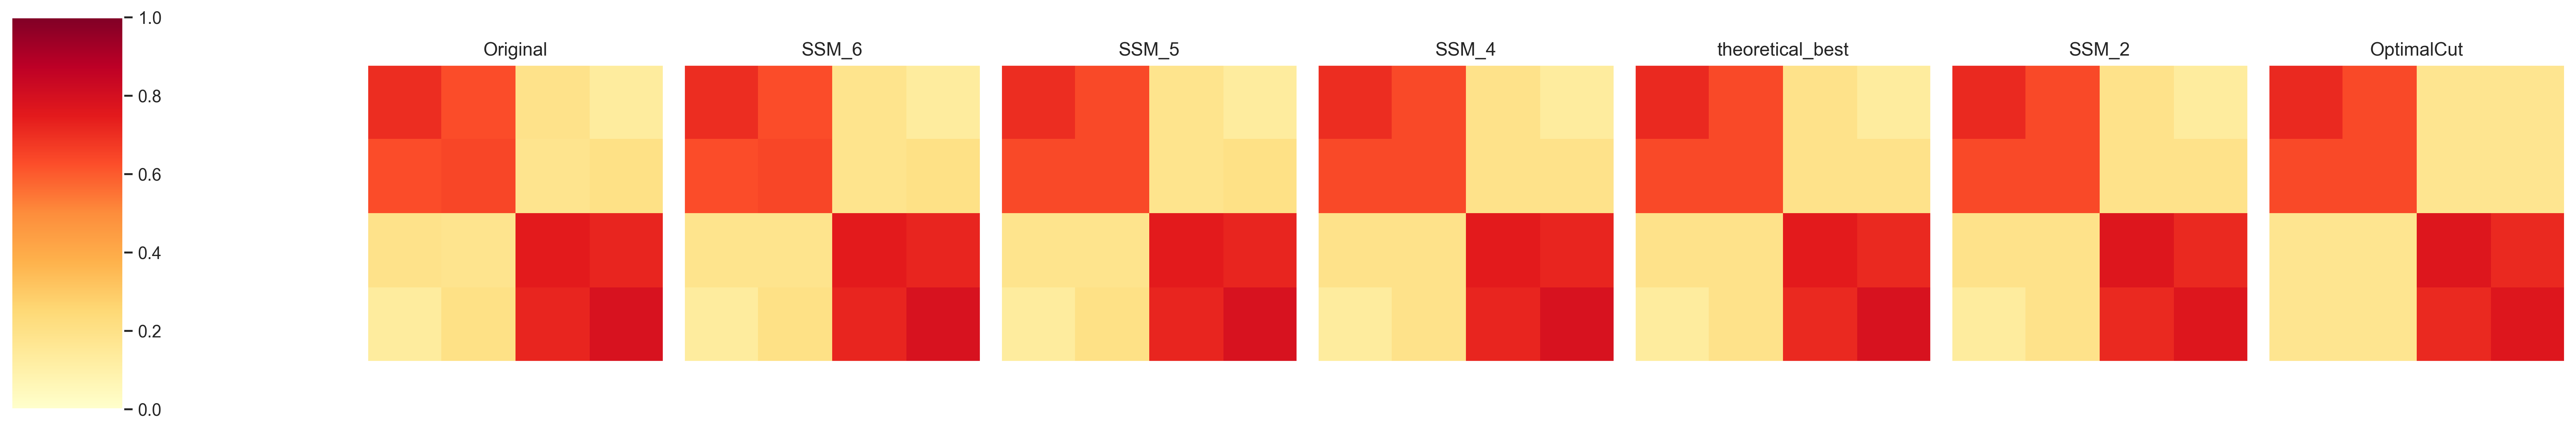

In [114]:
fig, axs = plt.subplots(1, len(est.all_cluster_graphons), figsize=(20, 5), dpi = 300)
nb_smoothnet_hist = len(est.all_cluster_graphons)
cbar_ax = fig.add_axes([-0.15, 0.15, 0.05, 0.7])
cmap_choice = cmap
for i in range(nb_smoothnet_hist):
    axs[i].imshow(transform(est.all_cluster_graphons[nb_smoothnet_hist-i-1].get_theta()), cmap=cmap_choice, interpolation='nearest', vmin=0, vmax=1)
    if i == 0:
        axs[i].set_title("Original")
    elif  np.allclose(est.all_cluster_graphons[nb_smoothnet_hist-i-1].get_theta(),est.best_pairs['bic']["graphon"].get_theta()):
        axs[i].set_title("OptimalCut")
    elif nb_smoothnet_hist-i ==3:
        axs[i].set_title("theoretical_best")
    elif i == nb_smoothnet_hist-1:
        axs[i].set_title("ER")
    else:
        axs[i].set_title("SSM_" + str(nb_smoothnet_hist-i))
    axs[i].set_xticks([])
    axs[i].set_yticks([])
    plt.tight_layout()
plt.colorbar(axs[i].imshow(transform(est.all_cluster_graphons[nb_smoothnet_hist-i-1].get_theta()), cmap=cmap_choice, interpolation='nearest', vmin=0, vmax=1), cax=cbar_ax)
fig.savefig("sankey_hierarchy.svg", dpi=600)
fig.savefig("sankey_hierarchy.pdf", dpi=600)

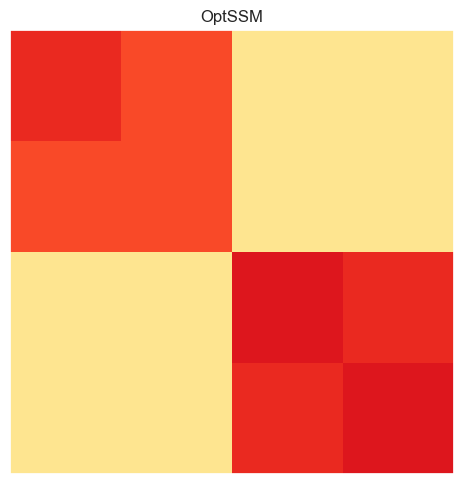

In [115]:
#Get SSM from selected one
selected_graphon = est.best_pairs['bic']["graphon"].get_theta()

fig, axs = plt.subplots(1, 1, figsize=(20, 5))
axs.imshow(selected_graphon, cmap=cmap, interpolation='nearest', vmin=0, vmax=1)
axs.set_title("OptSSM")
axs.set_xticks([])
axs.set_yticks([])
plt.tight_layout()

# Plotting criterion dynamic

In [116]:
from experiments.plot_network import sciplot_style
bic_val = np.array([109268.8720263047, 85839.50242516136, 85372.64211424408, 85299.42717747818,
           85116.44540877081, 85109.2023487274, 85111.49869994188, 85108.86516451511,
           85116.76006349441, 85124.21400949826][::-1])
n_LC = np.arange(1,len(bic_val)+1)
bic_val

array([ 85124.2140095 ,  85116.76006349,  85108.86516452,  85111.49869994,
        85109.20234873,  85116.44540877,  85299.42717748,  85372.64211424,
        85839.50242516, 109268.8720263 ])

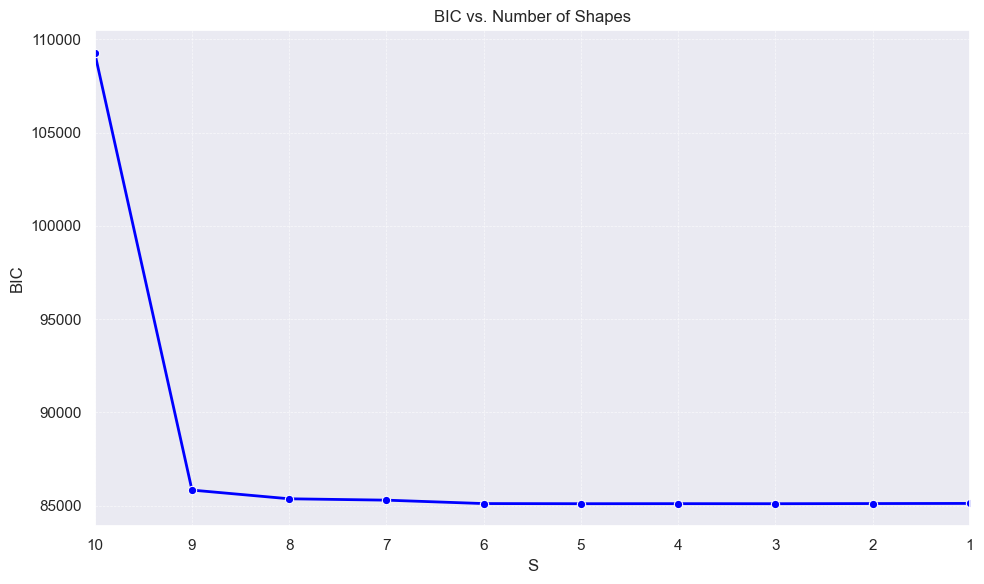

In [117]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_theme()

plt.figure(figsize=(10, 6))
#plt.plot(n_LC, bic_val, 'o-', color='blue', markersize=6, markerfacecolor='red', markeredgecolor='black')
sns.lineplot(x=n_LC, y=bic_val, marker="o", color='blue', linewidth=2)


#plt.yscale('log')
plt.xlim(len(bic_val),1)

plt.title('BIC vs. Number of Shapes')
plt.xlabel('S')
plt.ylabel('BIC')
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.savefig("bic_vs_nb_shapes.pdf", dpi=600)

plt.show()

